In [1]:
%pip install pandas numpy scipy statsmodels scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
import sys, os
from pathlib import Path
from IPython.display import Image, display

# Find the project folder (the one that contains "src"), wherever the notebook is opened from
def find_project_root(name="student_performance_project"):
    here = Path.cwd().resolve()
    # 1) current folder or any parent already is the project
    for p in [here, *here.parents]:
        if (p / "src").is_dir():
            return p
    # 2) project folder is inside the current folder or a parent
    for p in [here, *here.parents]:
        if (p / name / "src").is_dir():
            return p / name
    # 3) search a few levels down from the current folder
    for hit in here.rglob("src"):
        if hit.is_dir() and hit.parent.name == name:
            return hit.parent
    return None

ROOT = find_project_root()
if ROOT is None:
    raise FileNotFoundError(
        f"Could not find the 'student_performance_project' folder.\n"
        f"Notebook is running in: {Path.cwd()}\n"
        f"Fix: set ROOT manually, e.g. ROOT = Path(r'C:/Users/YourName/Documents/student_performance_project')"
    )

os.chdir(ROOT)                 # make the project folder the working folder
sys.path.insert(0, str(ROOT))  # so "from src.config import ..." works

import pandas as pd
pd.set_option("display.width", 160)
from src.config import FIG, TAB
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
print("Project folder:", ROOT)

Project folder: C:\Users\Acer\Downloads\student_performance_project\student_performance_project


In [4]:
from src.cleaning import load_and_clean
df, log = load_and_clean()
log.to_csv(TAB / "A_cleaning_log.csv", index=False)
print(log.to_string(index=False))
df.head()

                                  step  count
                              raw rows   1194
     attendance missing/invalid -> NaN      1
         study_hours > 16 h/day -> NaN      0
        social_hours > 16 h/day -> NaN      1
         skill_hours > 16 h/day -> NaN      0
                  semester > 12 -> NaN     36
CGPA <= 0 removed (no graded work yet)     39
                            clean rows   1155


,admission_year,gender,age,semester,scholarship,uni_transport,study_hours,study_sessions,learning_mode,smartphone,...,relationship,cocurricular,living_with,health_issue,prev_sgpa,disability,cgpa,credits,family_income,log_income
0,2018,Male,24,12.0,Yes,No,3.0,2,Offline,Yes,...,Single,Yes,Bachelor,No,2.68,No,3.15,75,25000,4.397940
1,2021,Male,22,4.0,Yes,Yes,3.0,2,Online,Yes,...,Single,Yes,Family,No,2.68,No,3.15,36,100000,5.000000
2,2020,Female,21,5.0,No,No,3.0,3,Offline,Yes,...,Single,No,Bachelor,No,2.68,No,3.15,50,50000,4.698970
3,2021,Male,20,4.0,Yes,No,1.0,3,Offline,Yes,...,Single,No,Bachelor,Yes,2.68,No,3.15,36,62488,4.795797
4,2021,Male,22,4.0,Yes,No,3.0,1,Online,Yes,...,Partnered,No,Bachelor,Yes,2.68,No,3.15,36,50000,4.698970


In [5]:
from src.analysis_real import run as run_real
a = run_real(df)
print(f"Students: {a['n']}   mean CGPA: {a['cgpa_mean']:.2f}")
print(f"Regression R2  without prior SGPA: {a['ols']['r2_without_prior']:.2f}   with prior SGPA: {a['ols']['r2_with_prior']:.2f}")
print(f"Prediction R2  without prior SGPA: {a['gbm']['r2_without_prior_mean']:.2f}   with prior SGPA: {a['gbm']['r2_with_prior_mean']:.2f}")

Students: 1155   mean CGPA: 3.27
Regression R2  without prior SGPA: 0.09   with prior SGPA: 0.58
Prediction R2  without prior SGPA: 0.05   with prior SGPA: 0.69


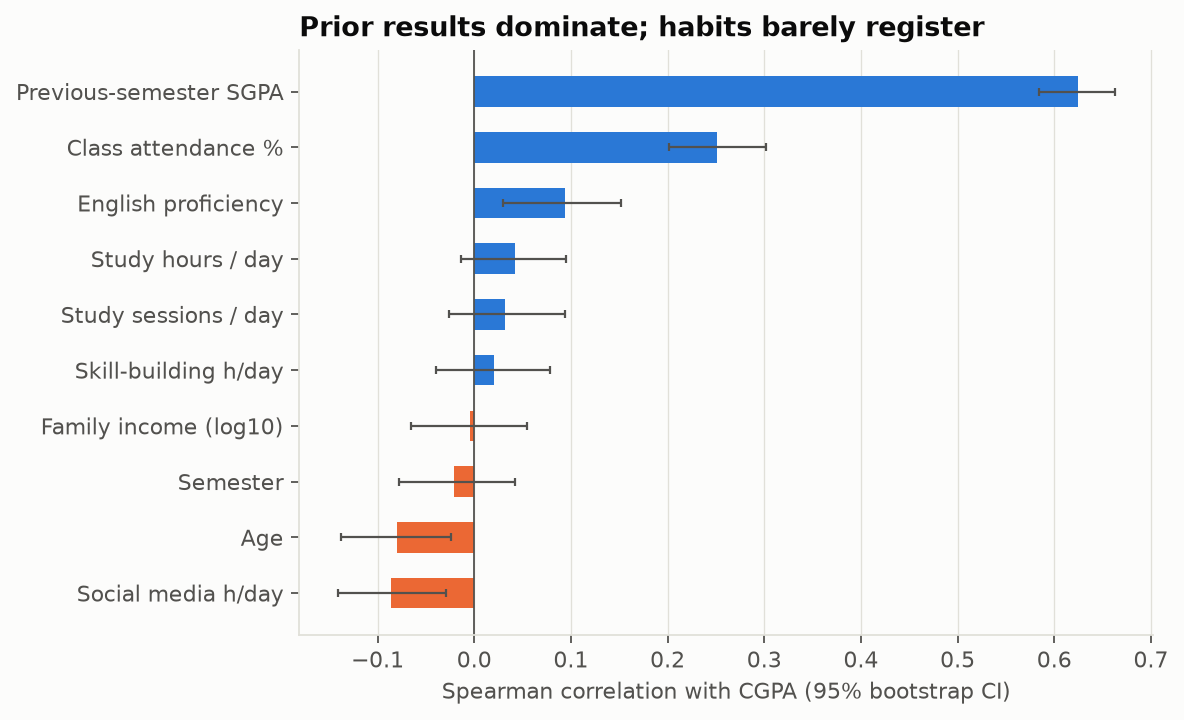

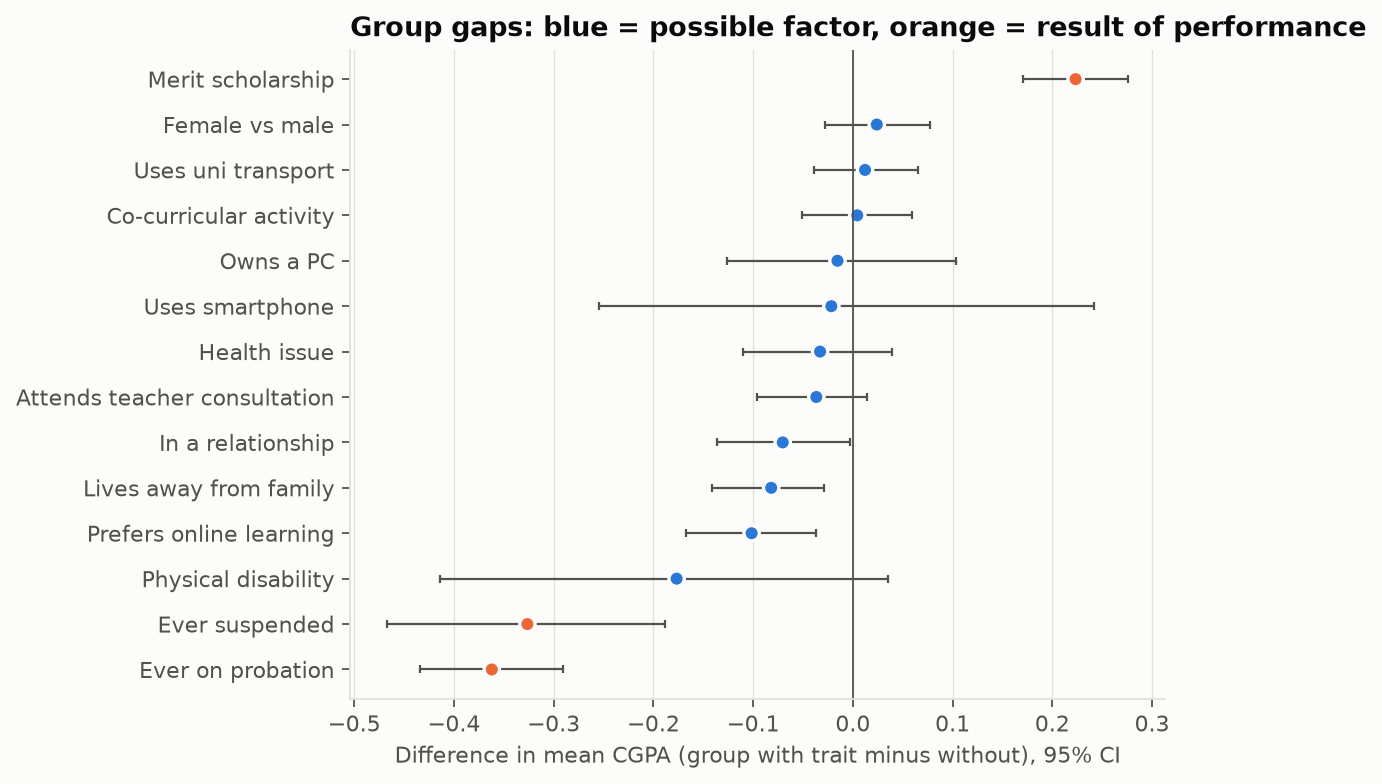

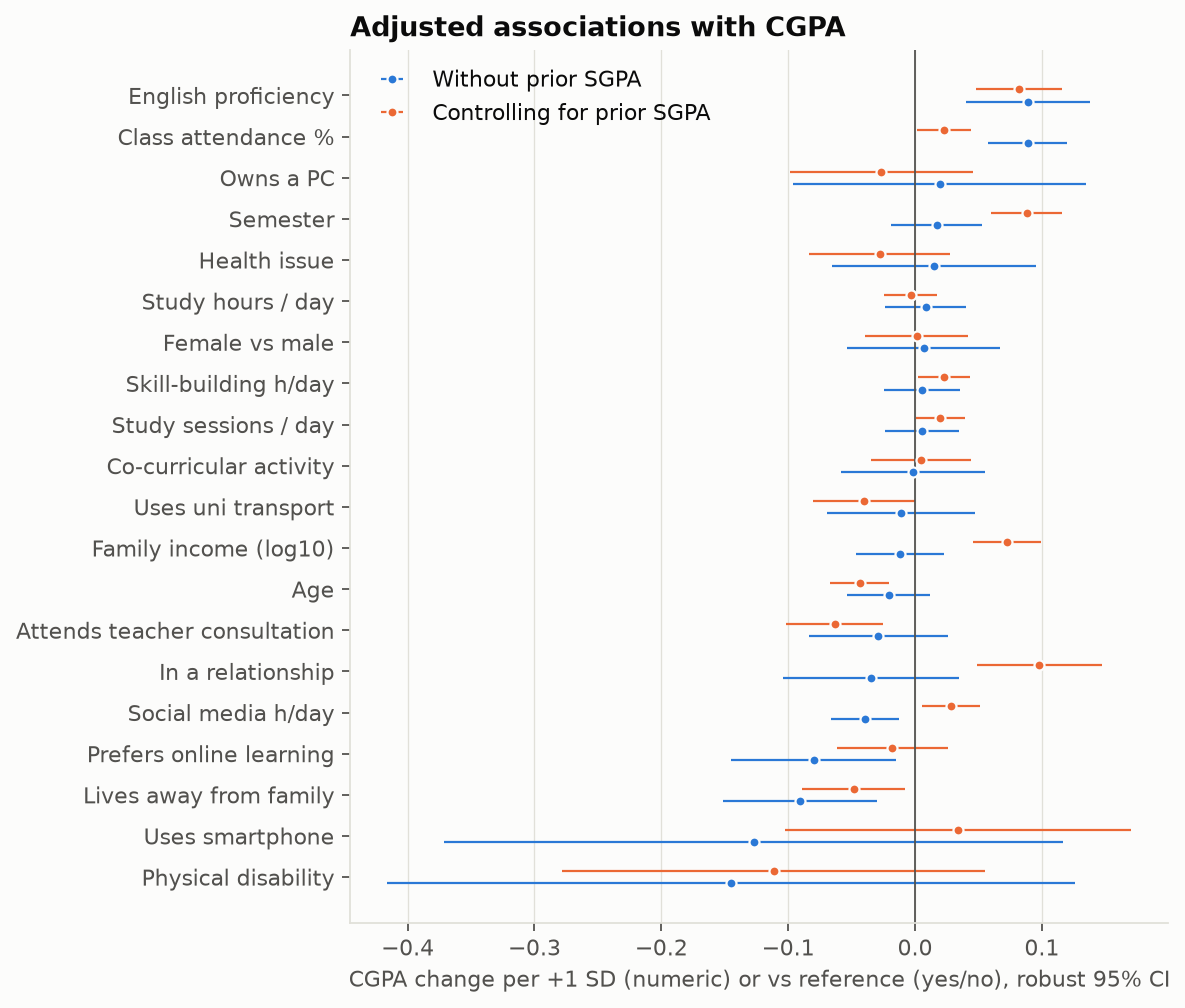

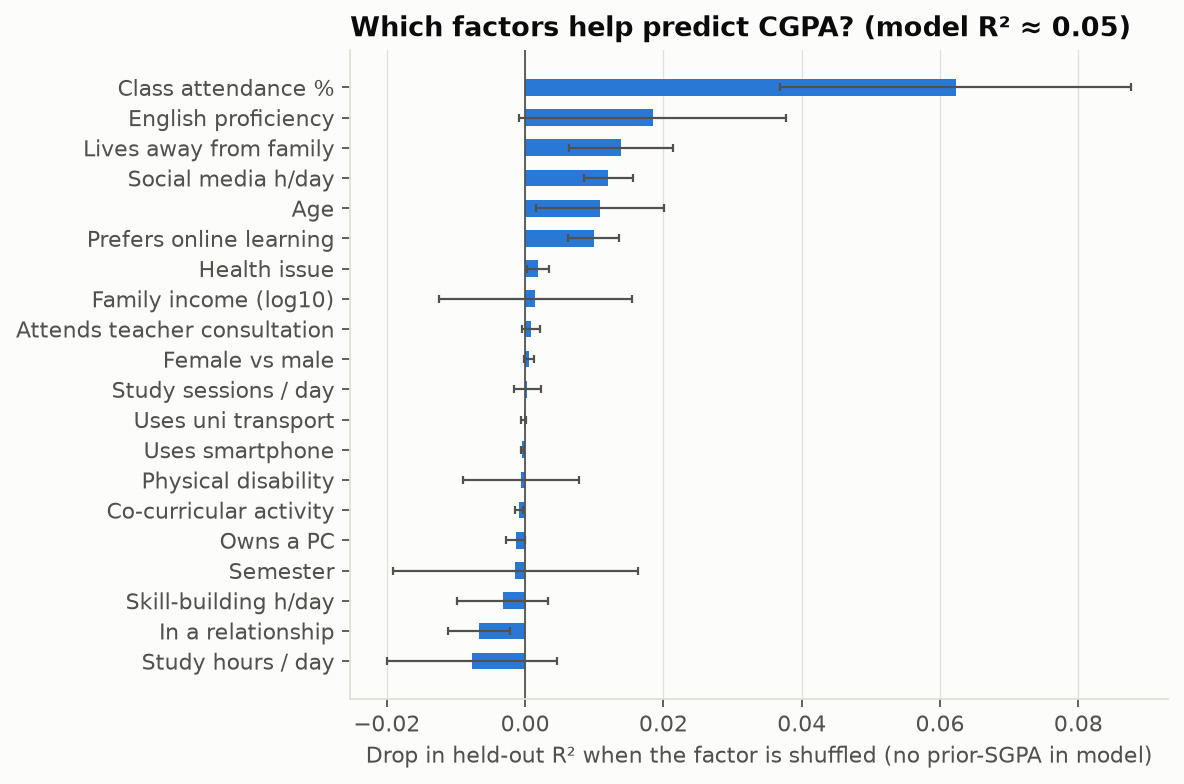

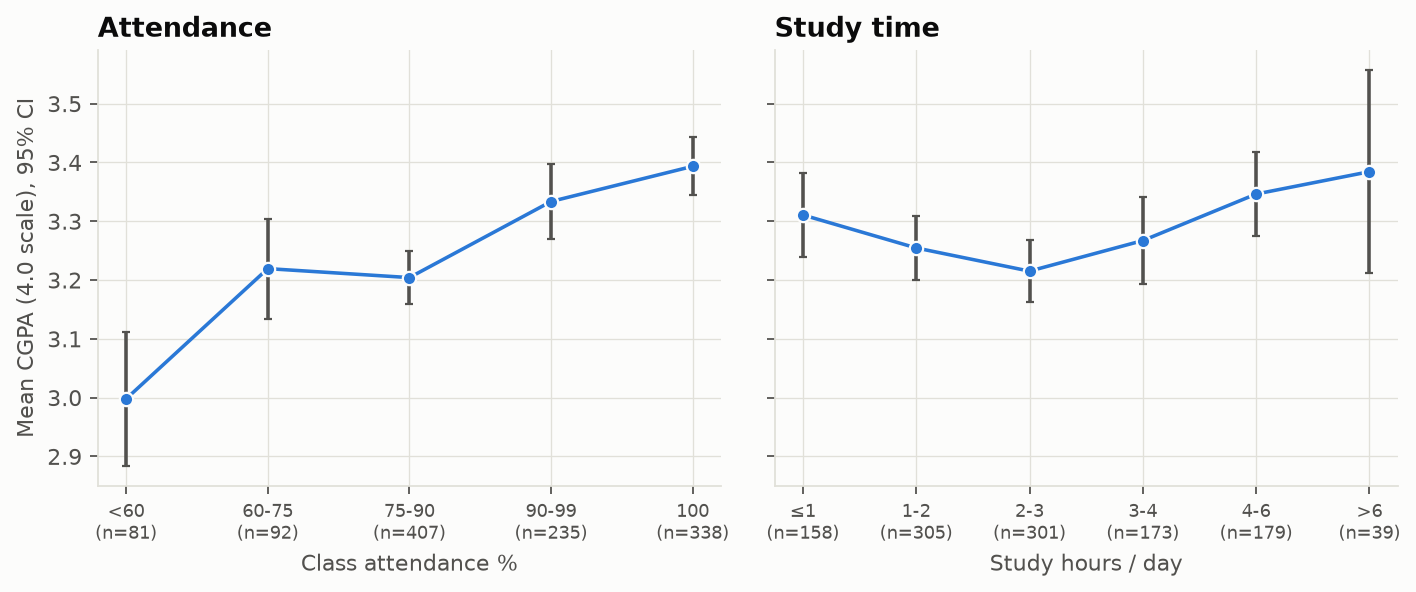

In [6]:
for f in ["A1_correlations", "A2_group_gaps", "A3_regression", "A4_importance", "A5_dose_response"]:
    display(Image(filename=str(FIG / f"{f}.png")))

In [7]:
from src.simulate import simulate
sim = simulate()
print(sim.shape)
sim.head()

(3500, 16)


,student_id,institution,tier,branch,gender,first_gen,hostel,mentor_access,paid_work,class12_pct,attendance,study_hours,sleep_hours,screen_hours,stress,cgpa
0,S00001,INST04,Tier 1,ME,Female,0,1,0,0,94.0,73.2,1.5,5.5,4.0,2.5,7.55
1,S00002,INST08,Tier 2,CSE,Female,1,1,0,0,70.4,55.6,2.9,NaN,NaN,3.9,5.97
2,S00003,INST08,Tier 2,AI,Female,1,1,1,0,78.2,100.0,1.3,5.6,6.0,8.3,7.28
3,S00004,INST10,Tier 3,ME,Female,0,0,0,0,69.1,64.7,1.9,5.2,1.7,8.2,6.65
4,S00005,INST02,Tier 1,CSE,Male,1,1,0,0,96.3,89.2,4.3,7.0,1.6,5.8,7.74


In [8]:
from src.analysis_india import run as run_india
b = run_india(sim)
print(f"Planted effects recovered inside the 95% interval: {b['mixed']['coverage']:.0%}")
print(f"Prediction R2: {b['gbm_r2']['mean']:.2f}")
print(f"Share of CGPA variance between institutions: {b['mixed']['icc_institution']:.2f}")

Planted effects recovered inside the 95% interval: 94%
Prediction R2: 0.60
Share of CGPA variance between institutions: 0.05


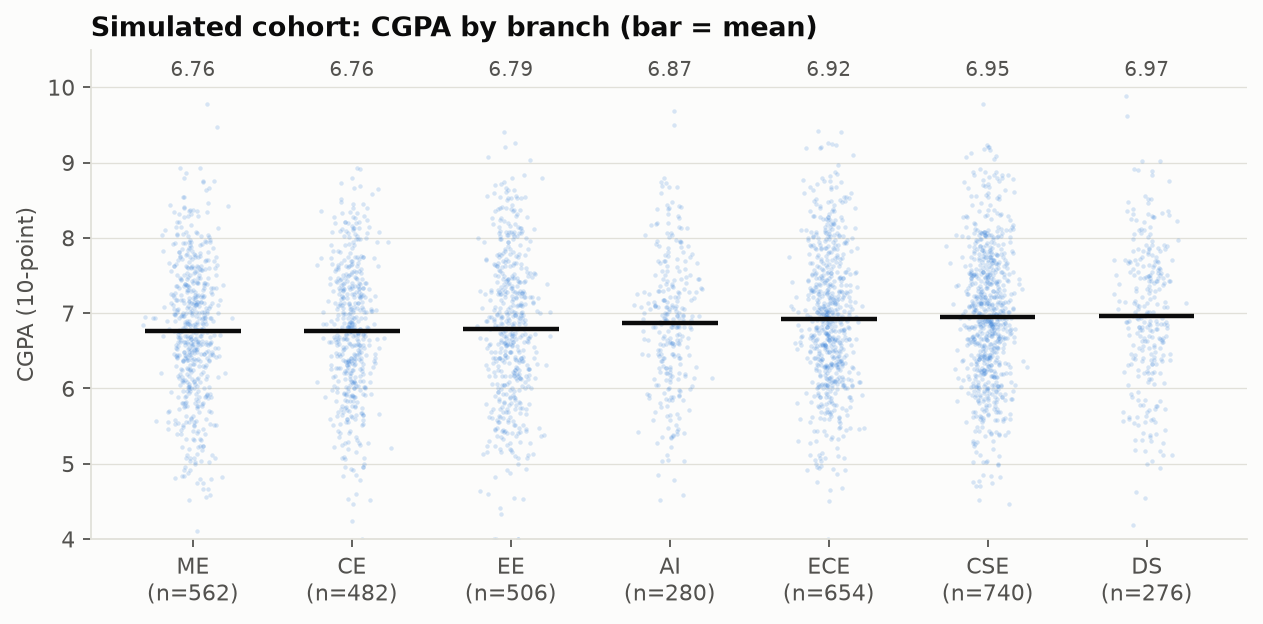

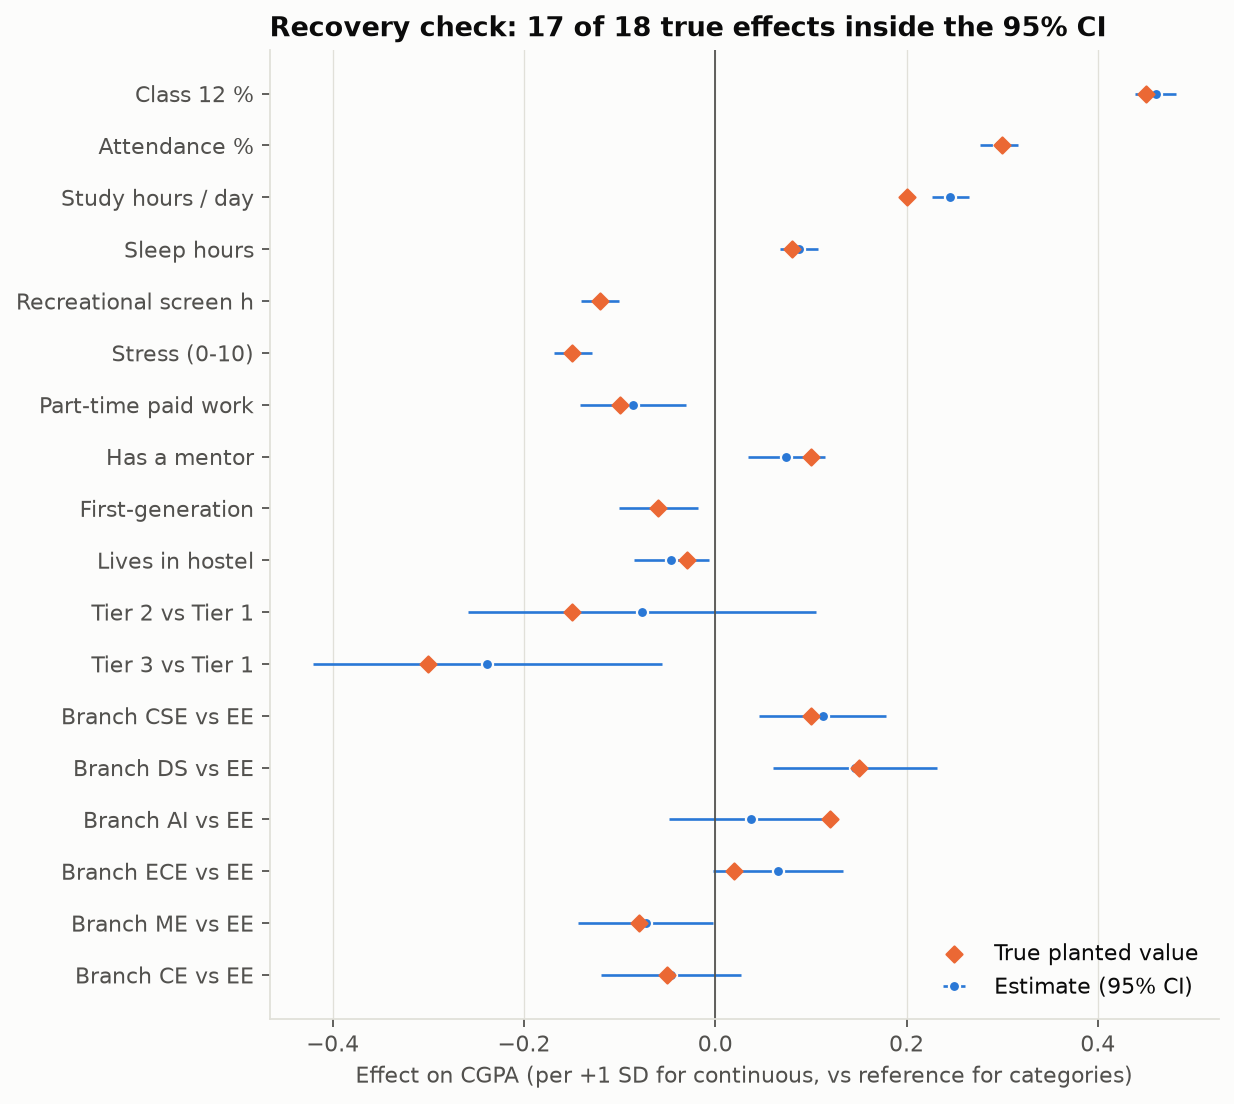

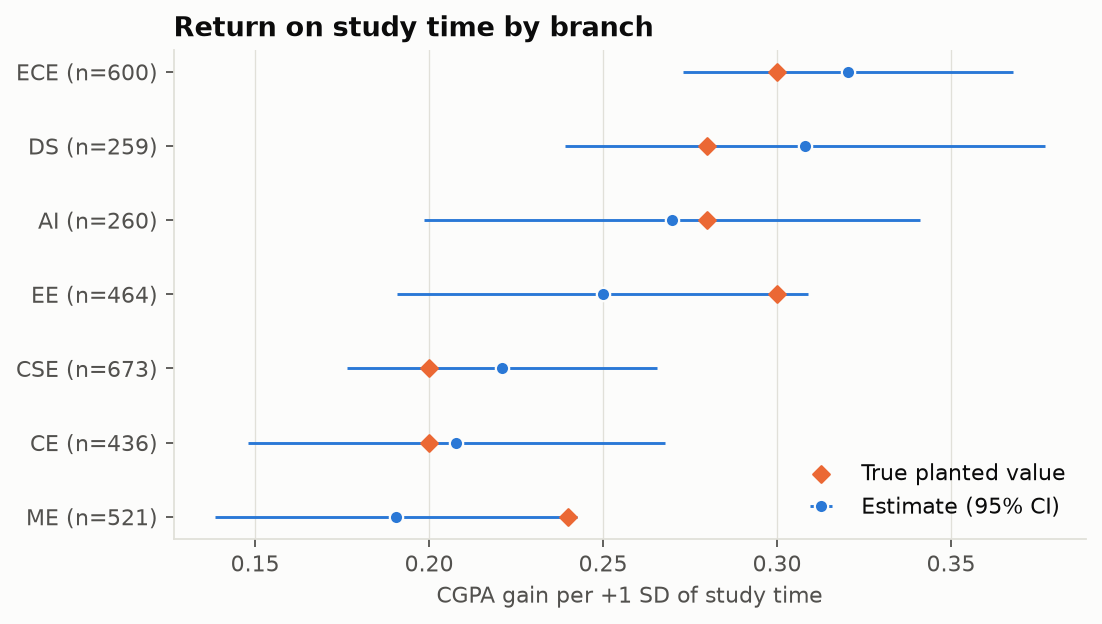

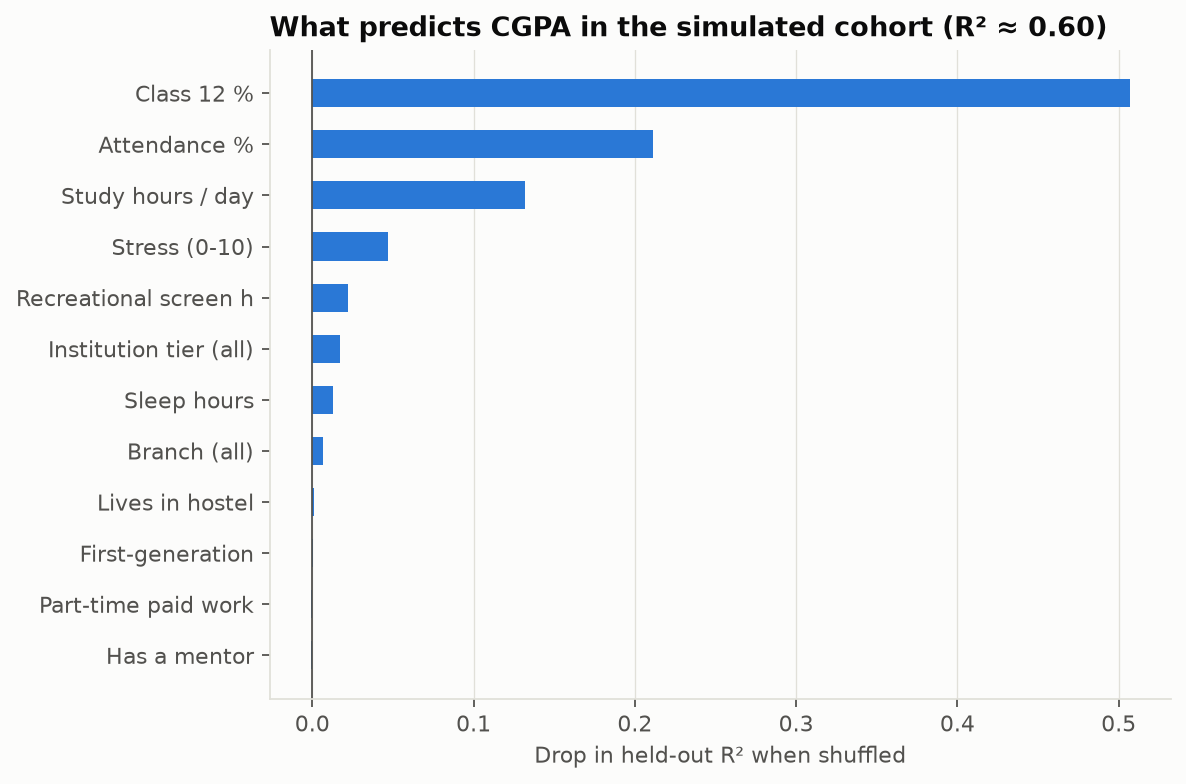

In [9]:
for f in ["B1_branch_cgpa", "B2_recovered_vs_true", "B3_study_by_branch", "B4_importance"]:
    display(Image(filename=str(FIG / f"{f}.png")))

In [10]:
pd.read_csv(TAB / "A_ols_coefficients.csv", index_col=0).round(3)

,m1_coef,m1_lo,m1_hi,m1_p,m2_coef,m2_lo,m2_hi,m2_p
age,-0.021,-0.054,0.012,0.213,-0.044,-0.067,-0.021,0.000
attendance,0.089,0.058,0.120,0.000,0.023,0.001,0.044,0.038
cocurricular,-0.002,-0.058,0.055,0.953,0.005,-0.035,0.044,0.811
consultancy,-0.029,-0.084,0.026,0.300,-0.063,-0.102,-0.025,0.001
disability,-0.145,-0.416,0.126,0.294,-0.112,-0.278,0.055,0.190
english_score,0.089,0.040,0.138,0.000,0.082,0.048,0.116,0.000
gender,0.007,-0.054,0.067,0.827,0.001,-0.039,0.042,0.953
health_issue,0.015,-0.065,0.095,0.715,-0.028,-0.083,0.027,0.323
learning_mode,-0.080,-0.145,-0.015,0.016,-0.018,-0.062,0.026,0.419
living_with,-0.091,-0.152,-0.030,0.003,-0.048,-0.089,-0.008,0.019


In [11]:
pd.read_csv(TAB / "B_recovered_vs_true.csv").round(3)

,effect,true,estimate,ci_lo,ci_hi,covered,error
0,Class 12 %,0.45,0.460,0.439,0.481,True,0.010
1,Attendance %,0.30,0.297,0.277,0.316,True,-0.003
2,Study hours / day,0.20,0.246,0.226,0.266,False,0.046
3,Sleep hours,0.08,0.087,0.068,0.107,True,0.007
4,Recreational screen h,-0.12,-0.121,-0.140,-0.101,True,-0.001
5,Stress (0-10),-0.15,-0.149,-0.169,-0.129,True,0.001
6,Part-time paid work,-0.10,-0.086,-0.142,-0.030,True,0.014
7,Has a mentor,0.10,0.074,0.034,0.115,True,-0.026
8,First-generation,-0.06,-0.059,-0.101,-0.018,True,0.001
9,Lives in hostel,-0.03,-0.046,-0.085,-0.006,True,-0.016
